# Step 1 - LoRA fine-tuning

Member A task: use the shared corpus, attach a LoRA adapter to DistilGPT2 attention projections, save the checkpoint, plot loss, and compare the same prompts before and after training.

In [10]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
from datasets import Dataset
from peft import LoraConfig, TaskType, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer, DataCollatorForLanguageModeling, Trainer, TrainingArguments

ROOT = next(path for path in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent] if (path / 'data' / 'cebuano_corpus.txt').exists())
CARL = ROOT / 'carl work' if (ROOT / 'carl work').exists() else ROOT
CORPUS = ROOT / 'data' / 'cebuano_corpus.txt'
CHECKPOINT = CARL / 'checkpoints' / 'lora_step1'
OUTPUTS = CARL / 'outputs'
MODEL_NAME = 'distilgpt2'
CHUNK_SIZE = 256
MAX_STEPS = 5  # smoke test; use -1 for the full configured run
print('Corpus:', CORPUS)
print('Checkpoint:', CHECKPOINT)

Corpus: d:\RANDOM\data\cebuano_corpus.txt
Checkpoint: d:\RANDOM\carl work\checkpoints\lora_step1


In [11]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
raw_text = CORPUS.read_text(encoding='utf-8')
token_ids = tokenizer.encode(raw_text)
chunks = [token_ids[index:index + CHUNK_SIZE] for index in range(0, len(token_ids) - CHUNK_SIZE + 1, CHUNK_SIZE)]
dataset = Dataset.from_dict({'input_ids': chunks}).train_test_split(test_size=0.1, seed=42)
print('Characters:', len(raw_text))
print('Tokens:', len(token_ids))
print('Chunks:', len(chunks))
print('Train/test:', dataset)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (563478 > 1024). Running this sequence through the model will result in indexing errors


Characters: 1472762
Tokens: 563478
Chunks: 2201
Train/test: DatasetDict({
    train: Dataset({
        features: ['input_ids'],
        num_rows: 1980
    })
    test: Dataset({
        features: ['input_ids'],
        num_rows: 221
    })
})


In [20]:
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
model.config.pad_token_id = tokenizer.eos_token_id
lora_config = LoraConfig(task_type=TaskType.CAUSAL_LM, r=8, lora_alpha=16, lora_dropout=0.1, target_modules=['c_attn'], bias='none')
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)
training_args = TrainingArguments(output_dir=str(CHECKPOINT), num_train_epochs=3, max_steps=MAX_STEPS, per_device_train_batch_size=2, gradient_accumulation_steps=8, save_steps=100, logging_steps=1, learning_rate=2e-4, fp16=False, report_to='none')
trainer = Trainer(model=model, args=training_args, train_dataset=dataset['train'], eval_dataset=dataset['test'], data_collator=data_collator)
trainer.train()
CHECKPOINT.mkdir(parents=True, exist_ok=True)
model.save_pretrained(CHECKPOINT)
tokenizer.save_pretrained(CHECKPOINT)
print('Saved checkpoint:', CHECKPOINT)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

c:\Users\aller\AppData\Local\Programs\Python\Python311\Lib\site-packages\peft\tuners\lora\layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(
c:\Users\aller\AppData\Local\Programs\Python\Python311\Lib\site-packages\transformers\modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


trainable params: 147,456 || all params: 82,060,032 || trainable%: 0.1797


c:\Users\aller\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
1,5.161053
2,5.424716
3,5.482818
4,5.670718
5,5.377195


Saved checkpoint: d:\RANDOM\carl work\checkpoints\lora_step1


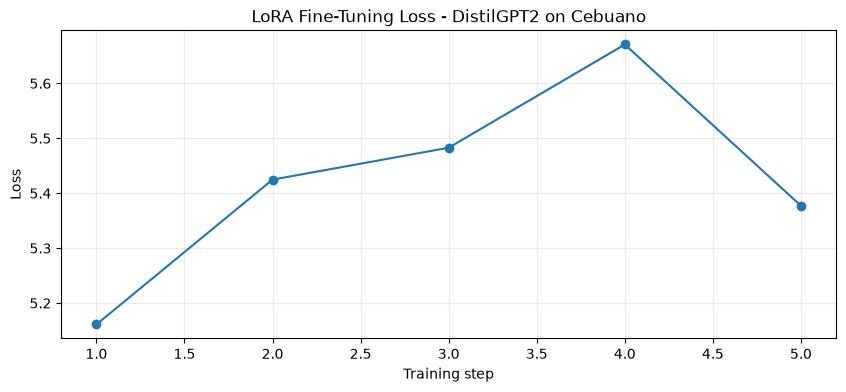

Final measured loss: 5.377194881439209


In [24]:
history = trainer.state.log_history
loss_rows = [row for row in history if 'loss' in row]
if not loss_rows:
    summary = next((row for row in reversed(history) if 'train_loss' in row), None)
    if summary is not None:
        loss_rows = [{'step': summary.get('step', MAX_STEPS), 'loss': summary['train_loss']}]
if not loss_rows:
    raise RuntimeError('No loss values were logged. Run the training cell first.')
with (OUTPUTS / 'step1_training_log.json').open('w', encoding='utf-8') as file:
    json.dump({'history': history, 'loss_rows': loss_rows, 'token_count': len(token_ids), 'chunk_count': len(chunks), 'chunk_size': CHUNK_SIZE}, file, indent=2)
steps = [row.get('step', index + 1) for index, row in enumerate(loss_rows)]
losses = [row['loss'] for row in loss_rows]
plt.figure(figsize=(10, 4))
plt.plot(steps, losses, marker='o')
plt.xlabel('Training step')
plt.ylabel('Loss')
plt.title('LoRA Fine-Tuning Loss - DistilGPT2 on Cebuano')
plt.grid(alpha=0.25)
plt.savefig(OUTPUTS / 'loss_curve.png', dpi=180, bbox_inches='tight')
plt.show()
print('Final measured loss:', losses[-1])

In [25]:
import torch
prompts = ['Ang mga estudyante sa Cebu', 'Nagsugod na ang', 'Ang kinabuhi sa', 'Miadto siya sa', 'Sa matag adlaw,']
base = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
base.eval()
model.eval()
with (OUTPUTS / 'step1_before_after.txt').open('w', encoding='utf-8') as file:
    for prompt in prompts:
        inputs = tokenizer(prompt, return_tensors='pt')
        with torch.no_grad():
            before = base.generate(**inputs, max_new_tokens=50, do_sample=False, pad_token_id=tokenizer.eos_token_id)
            after = model.generate(**inputs, max_new_tokens=50, do_sample=False, pad_token_id=tokenizer.eos_token_id)
        file.write(f'PROMPT: {prompt}\nBEFORE: {tokenizer.decode(before[0], skip_special_tokens=True)}\nAFTER: {tokenizer.decode(after[0], skip_special_tokens=True)}\n' + '-' * 80 + '\n')
print('Saved before/after comparison.')

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Saved before/after comparison.
